# EN4554 Assignment 1, Part 1: LoRA+ on SmolVLM-256M
## Notebook 04: testing the perception argument

**Claim being tested.** In the report we argue that LoRA+ did not help on TextVQA because TextVQA is hard here for
**perceptual** reasons: at 512×512 with no tiling, each image becomes only **64 visual tokens**, and small text is not
resolved. A learning-rate ratio cannot fix missing pixels.

**Test (no training needed).** Evaluate the *zero-shot* model on the **same 500 eval questions per task**, with the
**original full-resolution images**, at increasing visual-token budgets using SmolVLM's image tiling:

| setting | what the model sees | visual tokens per image |
|---|---|---|
| 256, no tiling (control) | image first shrunk to 256 px, then the same single 512×512 view | 64 |
| 512, no tiling | one 512×512 view (as in all our experiments) | 64 |
| tiling ≤1024 px | up to 2×2 tiles of 512 px + a global view | ≤ 320 |
| tiling ≤1536 px | up to 3×3 tiles + global view | ≤ 640 |
| tiling ≤2048 px | up to 4×4 tiles + global view (SmolVLM's default) | ≤ 1088 |

**Predictions.** If TextVQA is perception-limited at 512 px, it should be much more sensitive to image detail than
VQAv2, whose questions are mostly about large objects, colours and counts:
* **P1 (less detail):** shrinking images to 256 px should hurt TextVQA **more** than VQAv2.
* **P2 (more detail):** tiling at high resolution should help TextVQA **more** than VQAv2.

Both are tested as a *difference of changes* between the two tasks, with a paired bootstrap over the same questions.
**Why compare tasks, not just settings:** tiling also changes the input *format* (extra tile tokens and row/column
markers, and SmolVLM was trained with tiling on). Any format effect that hits both tasks cancels in the difference. P1
keeps the format identical and changes only the detail, so it does not depend on this at all.
If the predictions fail, the perception argument is wrong.

Runtime used: **T4 GPU**

In [ ]:
!pip install -q "transformers==5.19.0" "peft==0.21.2" "datasets==5.1.0" accelerate
!pip uninstall -y -q torchao

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import os, sys, re, io, json, time, random, shutil
import numpy as np
import torch

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/EN4554_LoRAplus"
else:
    ROOT = "./EN4554_LoRAplus"
DATA_DIR, RES_DIR = f"{ROOT}/data", f"{ROOT}/results"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
SEED = 42
MODEL_ID = "HuggingFaceTB/SmolVLM-256M-Instruct"
N_EVAL = None            # None = all 500 questions (set a small number only for a quick test)

SETTINGS = [  # (name, do_image_splitting, longest_edge, eval batch size, shrink image to this many px first)
    ("256_notiling", False, None, 32, 256),   # control: same input format as 512_notiling, but less detail
    ("512_notiling", False, None, 32, None),  # what all our experiments used (64 visual tokens)
    ("tile_1024",    True,  1024, 16, None),
    ("tile_1536",    True,  1536, 8,  None),
    ("tile_2048",    True,  2048, 8,  None),
]
import transformers, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__,
      "| device", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Mounted at /content/drive
torch 2.14.1+cu130 | transformers 5.19.0 | datasets 5.1.0 | device cuda Tesla T4


## 1. Rebuild the eval sets at full resolution
The subsets saved by notebook 01 contain images shrunk to 512 px, which is no use for a resolution test. So we
re-download the **same** data files that notebook 01 sampled (the same seeded choice), and pick out the **same 500
questions** (matched by question id), this time keeping the original images. The result is saved to Drive as
`*_eval_fullres`. The question order is identical to the saved subsets, so scores can be compared question by question.

In [ ]:
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download
from datasets import Dataset, Features, Value, Image, List, load_from_disk

EVAL_SOURCES = {"textvqa_eval": ("lmms-lab/textvqa", "validation", 1),   # same as notebook 01
                "vqav2_eval":   ("lmms-lab/VQAv2",   "validation", 2)}
FEATURES = Features({"qid": Value("string"), "image_id": Value("string"), "task": Value("string"),
                     "question": Value("string"), "answers": List(Value("string")), "image": Image()})

def build_fullres(name):
    path, tmp = f"{DATA_DIR}/{name}_fullres", f"{DATA_DIR}/{name}_fullres__tmp"
    if os.path.exists(path):
        print(f"{name}_fullres: already on Drive, loading")
        return load_from_disk(path)
    small = load_from_disk(f"{DATA_DIR}/{name}")
    want = set(small["qid"])
    repo, split, n_files = EVAL_SOURCES[name]
    all_files = sorted(f for f in HfApi().list_repo_files(repo, repo_type="dataset")
                       if f.startswith(f"data/{split}-") and f.endswith(".parquet"))
    first = sorted(random.Random(f"{SEED}-{name}").sample(all_files, n_files))      # notebook 01's choice
    found = {}
    for f in first + [x for x in all_files if x not in first]:                     # fall back to other files if needed
        if len(found) == len(want):
            break
        p = hf_hub_download(repo, f, repo_type="dataset")
        pf = pq.ParquetFile(p)
        for rg in range(pf.num_row_groups):
            ids = [str(q) for q in pf.read_row_group(rg, columns=["question_id"]).column(0).to_pylist()]
            hit = [k for k, q in enumerate(ids) if q in want]
            if hit:
                tbl = pf.read_row_group(rg, columns=["question_id", "image"])
                for k in hit:
                    found[ids[k]] = tbl.slice(k, 1).to_pylist()[0]["image"]["bytes"]
        print(f"   {f.split('/')[-1]}: {len(found)}/{len(want)} questions found", flush=True)
    assert len(found) == len(want), "some questions were not found"

    def gen():
        for ex in small.remove_columns("image"):                         # same order as the saved subset
            yield dict(ex, image={"bytes": found[ex["qid"]], "path": None})
    ds = Dataset.from_generator(gen, features=FEATURES)
    shutil.rmtree(tmp, ignore_errors=True)
    ds.save_to_disk(tmp); os.rename(tmp, path)
    return load_from_disk(path)

full = {"textvqa": build_fullres("textvqa_eval"), "vqav2": build_fullres("vqav2_eval")}
for t, d in full.items():
    sizes = np.array([im.size for im in d.select(range(min(100, len(d))))["image"]])
    print(f"{t:8s} {len(d)} questions | original image size (first 100): median {np.median(sizes, 0).astype(int).tolist()} "
          f"(w,h), max side {sizes.max()}")

data/validation-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  311MB            

data/validation-00001-of-00003.parquet: downloading bytes:           |  0.00B            

   validation-00001-of-00003.parquet: 500/500 questions found


Generating train split: 0 examples [00:00, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/500 [00:00<?, ? examples/s]

data/validation-00002-of-00068.parquet: reconstructing file:   0%|          |  0.00B / 98.5MB            

... (4 outputs left out)

   validation-00024-of-00068.parquet: 500/500 questions found


Generating train split: 0 examples [00:00, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/500 [00:00<?, ? examples/s]

textvqa  500 questions | original image size (first 100): median [1024, 768] (w,h), max side 1024
vqav2    500 questions | original image size (first 100): median [640, 480] (w,h), max side 640


## 2. Prompt and metric (identical to notebooks 01–03)

In [ ]:
PROMPT_SUFFIX = " Answer the question using a single word or phrase."
_CONTRACTIONS = {"dont": "don't", "doesnt": "doesn't", "isnt": "isn't", "arent": "aren't", "cant": "can't",
                 "wont": "won't", "didnt": "didn't", "wasnt": "wasn't", "werent": "weren't", "couldnt": "couldn't",
                 "shouldnt": "shouldn't", "wouldnt": "wouldn't", "hasnt": "hasn't", "havent": "haven't",
                 "im": "i'm", "ive": "i've", "youre": "you're", "theyre": "they're", "thats": "that's",
                 "whats": "what's", "wheres": "where's", "hes": "he's", "shes": "she's", "lets": "let's"}
_NUMS = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
         "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
_ARTICLES = {"a", "an", "the"}
_PUNCT = [";", "/", "[", "]", '"', "{", "}", "(", ")", "=", "+", "\\", "_", "-", ">", "<", "@", "`", ",", "?", "!"]
_PERIOD = re.compile(r"(?!<=\d)(\.)(?!\d)")
_COMMA = re.compile(r"(\d)(,)(\d)")

def normalize_answer(s):
    s = s.replace("\n", " ").replace("\t", " ").strip().lower()
    out = s
    for p in _PUNCT:
        if (p + " " in s or " " + p in s) or _COMMA.search(s):
            out = out.replace(p, "")
        else:
            out = out.replace(p, " ")
    out = _PERIOD.sub("", out)
    words = []
    for w in out.split():
        w = _NUMS.get(w, w)
        if w in _ARTICLES:
            continue
        words.append(_CONTRACTIONS.get(w, w))
    return " ".join(words)

def vqa_score(pred, answers):
    p = normalize_answer(pred)
    gts = [normalize_answer(a) for a in answers]
    return float(np.mean([min(1.0, sum(g == p for g in gts[:i] + gts[i + 1:]) / 3.0) for i in range(len(gts))]))

assert vqa_score("Stop.", ["stop"] * 10) == 1.0 and vqa_score("two", ["2"] * 10) == 1.0

## 3. Zero-shot evaluation at each resolution
Same model, same prompt, same questions, greedy decoding. Only the image processing changes.
Every setting's per-question predictions and scores are saved to `results/resolution_<task>.jsonl` (resumable).

In [ ]:
from transformers import AutoProcessor, AutoModelForImageTextToText

model = AutoModelForImageTextToText.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE).eval()

def res_file(task):
    return f"{RES_DIR}/resolution_{task}.jsonl"

def load_res(task):
    if not os.path.exists(res_file(task)):
        return {}
    with open(res_file(task)) as f:
        return {r["setting"]: r for r in map(json.loads, f) if r}

@torch.no_grad()
def shrink(im, px):
    im = im.convert("RGB")
    if px:
        im = im.copy(); im.thumbnail((px, px))
    return im

def run_setting(task, name, split, longest, bs, pre):
    kw = {"do_image_splitting": split}
    if longest:
        kw["size"] = {"longest_edge": longest}
    proc = AutoProcessor.from_pretrained(MODEL_ID, **kw)
    proc.tokenizer.padding_side = "left"
    img_tok = proc.tokenizer.convert_tokens_to_ids("<image>")
    data = full[task] if N_EVAL is None else full[task].select(range(N_EVAL))
    preds, ntok, t0 = [], [], time.time()
    for i in range(0, len(data), bs):
        chunk = data[i:i + bs]
        msgs = [[{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": q + PROMPT_SUFFIX}]}]
                for q in chunk["question"]]
        texts = [proc.apply_chat_template(m, add_generation_prompt=True) for m in msgs]
        b = proc(text=texts, images=[[shrink(im, pre)] for im in chunk["image"]], return_tensors="pt", padding=True).to(DEVICE)
        b["pixel_values"] = b["pixel_values"].to(DTYPE)
        ntok += (b["input_ids"] == img_tok).sum(1).tolist()
        out = model.generate(**b, max_new_tokens=10, do_sample=False)
        preds += [s.strip() for s in proc.batch_decode(out[:, b["input_ids"].shape[1]:], skip_special_tokens=True)]
    scores = [vqa_score(p, a) for p, a in zip(preds, data["answers"])]
    return {"task": task, "setting": name, "do_image_splitting": split, "longest_edge": longest,
            "acc": 100 * float(np.mean(scores)), "se": 100 * float(np.std(scores, ddof=1) / np.sqrt(len(scores))),
            "pre_shrink": pre, "mean_image_tokens": float(np.mean(ntok)), "n": len(scores), "time_s": round(time.time() - t0),
            "preds": preds, "scores": scores}

for name, split, longest, bs, pre in SETTINGS:
    for task in ("textvqa", "vqav2"):
        if name in load_res(task):
            print(f"{task:8s} {name:13s} already done"); continue
        try:
            rec = run_setting(task, name, split, longest, bs, pre)
        except torch.cuda.OutOfMemoryError:                       # retry with a smaller batch if the GPU runs out of memory
            torch.cuda.empty_cache()
            rec = run_setting(task, name, split, longest, max(1, bs // 4), pre)
        with open(res_file(task), "a") as f:
            f.write(json.dumps(rec) + "\n")
        print(f"{task:8s} {name:13s} acc {rec['acc']:5.1f} ± {1.96*rec['se']:.1f} | "
              f"{rec['mean_image_tokens']:6.0f} visual tokens/image | {rec['time_s']}s", flush=True)

config.json:   0%|          | 0.00/7.35k [00:00<?, ?B/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B /  513MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

... (6 outputs left out)

added_tokens.json:   0%|          | 0.00/4.74k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.55M [00:00<?, ?B/s]

textvqa  256_notiling  acc  28.4 ± 3.8 |     64 visual tokens/image | 36s
vqav2    256_notiling  acc  43.7 ± 4.2 |     64 visual tokens/image | 34s
textvqa  512_notiling  acc  31.6 ± 4.0 |     64 visual tokens/image | 34s
vqav2    512_notiling  acc  45.3 ± 4.2 |     64 visual tokens/image | 29s
textvqa  tile_1024     acc  48.8 ± 4.2 |    317 visual tokens/image | 82s
vqav2    tile_1024     acc  64.3 ± 4.0 |    318 visual tokens/image | 77s
textvqa  tile_1536     acc  50.6 ± 4.2 |    570 visual tokens/image | 152s
vqav2    tile_1536     acc  65.0 ± 4.0 |    570 visual tokens/image | 138s
textvqa  tile_2048     acc  49.1 ± 4.2 |    882 visual tokens/image | 227s
vqav2    tile_2048     acc  64.4 ± 4.0 |    853 visual tokens/image | 204s


## 4. Is TextVQA more sensitive to image detail than VQAv2? (P1, P2)
* **Per task:** change = accuracy(setting) − accuracy(512, no tiling), with a paired bootstrap 95% CI over the 500 questions.
* **P1:** change(TextVQA) − change(VQAv2) < 0 at 256 px (TextVQA loses more).
* **P2:** change(TextVQA) − change(VQAv2) > 0 at the highest tiling setting (TextVQA gains more).
* For reference, the dashed lines in the figure show our **best finetuned** accuracy at 512 px (notebook 03, LoRA tuned, 3 seeds).


textvqa:
   256_notiling  acc  28.4 ± 3.8  (   64 tok/img)   gain vs 512:  -3.3 [-6.7, +0.1]
   512_notiling  acc  31.6 ± 4.0  (   64 tok/img)   gain vs 512:  +0.0 [+0.0, +0.0]
   tile_1024     acc  48.8 ± 4.2  (  317 tok/img)   gain vs 512: +17.2 [+13.2, +21.3]
   tile_1536     acc  50.6 ± 4.2  (  570 tok/img)   gain vs 512: +19.0 [+15.1, +23.0]
   tile_2048     acc  49.1 ± 4.2  (  882 tok/img)   gain vs 512: +17.5 [+13.5, +21.5]

vqav2:
   256_notiling  acc  43.7 ± 4.2  (   64 tok/img)   gain vs 512:  -1.6 [-4.6, +1.4]
   512_notiling  acc  45.3 ± 4.2  (   64 tok/img)   gain vs 512:  +0.0 [+0.0, +0.0]
   tile_1024     acc  64.3 ± 4.0  (  318 tok/img)   gain vs 512: +19.0 [+15.0, +23.1]
   tile_1536     acc  65.0 ± 4.0  (  570 tok/img)   gain vs 512: +19.7 [+15.7, +23.7]
   tile_2048     acc  64.4 ± 4.0  (  853 tok/img)   gain vs 512: +19.1 [+15.1, +23.2]

P1 (less detail, same format): change(TextVQA) − change(VQAv2) at 256_notiling = -1.7 points, 95% CI [-6.2, +2.9]   (predicted < 

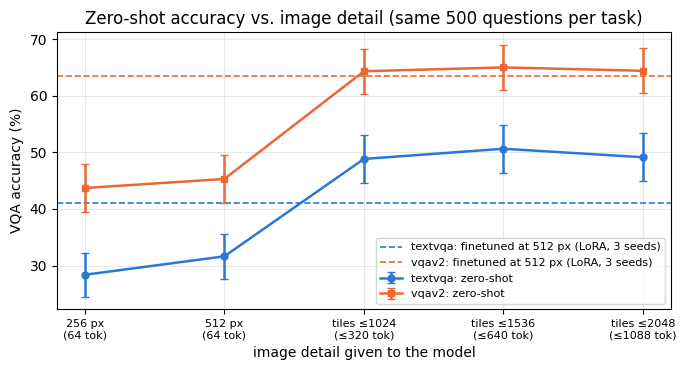

In [ ]:
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)

def boot(d, n=20000):
    m = d[rng.integers(0, len(d), size=(n, len(d)))].mean(1)
    return 100 * d.mean(), 100 * np.percentile(m, 2.5), 100 * np.percentile(m, 97.5), 100 * m

R = {t: load_res(t) for t in ("textvqa", "vqav2")}
names = [s[0] for s in SETTINGS]
summary, gain_boot = {}, {}
for t in R:
    base = np.array(R[t]["512_notiling"]["scores"])
    print(f"\n{t}:")
    for nm in names:
        if nm not in R[t]:
            continue
        r = R[t][nm]
        g, lo, hi, gb = boot(np.array(r["scores"]) - base)
        summary[f"{t}|{nm}"] = {"acc": r["acc"], "ci95": 1.96 * r["se"], "tokens": r["mean_image_tokens"],
                                "gain_vs_512": g, "gain_ci": [lo, hi]}
        gain_boot[(t, nm)] = gb
        print(f"   {nm:13s} acc {r['acc']:5.1f} ± {1.96*r['se']:.1f}  ({r['mean_image_tokens']:5.0f} tok/img)   "
              f"gain vs 512: {g:+5.1f} [{lo:+.1f}, {hi:+.1f}]")

print()
for label, nm, sign in [("P1 (less detail, same format)", "256_notiling", -1), ("P2 (more detail via tiling)", names[-1], +1)]:
    if ("textvqa", nm) in gain_boot and ("vqav2", nm) in gain_boot:
        dd = gain_boot[("textvqa", nm)] - gain_boot[("vqav2", nm)]
        d0 = summary[f"textvqa|{nm}"]["gain_vs_512"] - summary[f"vqav2|{nm}"]["gain_vs_512"]
        lo, hi = np.percentile(dd, 2.5), np.percentile(dd, 97.5)
        ok = (lo > 0) if sign > 0 else (hi < 0)
        summary[f"{label.split()[0]}_difference"] = {"setting": nm, "diff": d0, "ci": [lo, hi], "supported": bool(ok)}
        print(f"{label}: change(TextVQA) − change(VQAv2) at {nm} = {d0:+.1f} points, 95% CI [{lo:+.1f}, {hi:+.1f}]"
              f"   (predicted {'< 0' if sign < 0 else '> 0'}) -> {'SUPPORTED' if ok else 'NOT supported'}")

ft = {}
p = f"{RES_DIR}/seeds_summary.json"
if os.path.exists(p):
    s = json.load(open(p))
    ft = {t: s.get(f"{t}|LoRA-best", {}).get("acc_mean") for t in ("textvqa", "vqav2")}
    print("finetuned at 512 px (LoRA tuned, 3 seeds):", {k: round(v, 1) for k, v in ft.items() if v})
json.dump(summary, open(f"{RES_DIR}/resolution_summary.json", "w"), indent=2)

fig, ax = plt.subplots(figsize=(7, 3.8))
xlab = {"256_notiling": "256 px\n(64 tok)", "512_notiling": "512 px\n(64 tok)", "tile_1024": "tiles ≤1024\n(≤320 tok)",
        "tile_1536": "tiles ≤1536\n(≤640 tok)", "tile_2048": "tiles ≤2048\n(≤1088 tok)"}
for t, c, m in [("textvqa", "#2a78d6", "o"), ("vqav2", "#eb6834", "s")]:
    xs = [i for i, nm in enumerate(names) if nm in R[t]]
    y = [R[t][names[i]]["acc"] for i in xs]; e = [1.96 * R[t][names[i]]["se"] for i in xs]
    ax.errorbar(xs, y, yerr=e, color=c, marker=m, ms=5, lw=1.8, capsize=3, label=f"{t}: zero-shot")
    if ft.get(t):
        ax.axhline(ft[t], color=c, ls="--", lw=1.2, label=f"{t}: finetuned at 512 px (LoRA, 3 seeds)")
ax.set_xticks(range(len(names)), [xlab.get(n, n) for n in names], fontsize=8)
ax.set_xlabel("image detail given to the model"); ax.set_ylabel("VQA accuracy (%)")
ax.set_title("Zero-shot accuracy vs. image detail (same 500 questions per task)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{RES_DIR}/resolution_curve.png", dpi=200); plt.show()